# Q2. Mỗi năm kinh nghiệm làm tăng lương bao nhiêu? Có khác giữa các ngành?
**Người phụ trách:** Đăng

**Phương pháp:** trung vị lương theo `experience_level`; hồi quy tuyến tính `log(lương) ~ experience_months` cho
toàn bộ và cho 8 ngành nhiều tin nhất → % tăng lương mỗi năm = `exp(12·β) − 1`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.cleaning import load_clean, EXPERIENCE_LEVELS, REGIONS, CATEGORY_LABELS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_clean()
df["cat"] = df["category"].map(CATEGORY_LABELS)
# Tập có lương hợp lệ: bỏ "Thoả thuận" và ngoại lai
sal = df[~df["salary_negotiable"] & ~df["salary_outlier"]].copy()
print(f"Tất cả tin: {len(df):,} | Tin có lương hợp lệ: {len(sal):,}")

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

Tất cả tin: 36,457 | Tin có lương hợp lệ: 25,796


## 1. Lương theo mức kinh nghiệm

,count,median,mean
experience_level,,,
Không yêu cầu,6674,10.0,12.1
Dưới 1 năm,1517,11.0,12.8
1-2 năm,13814,13.0,15.0
3-5 năm,3732,19.0,22.1
Trên 5 năm,59,37.0,40.2


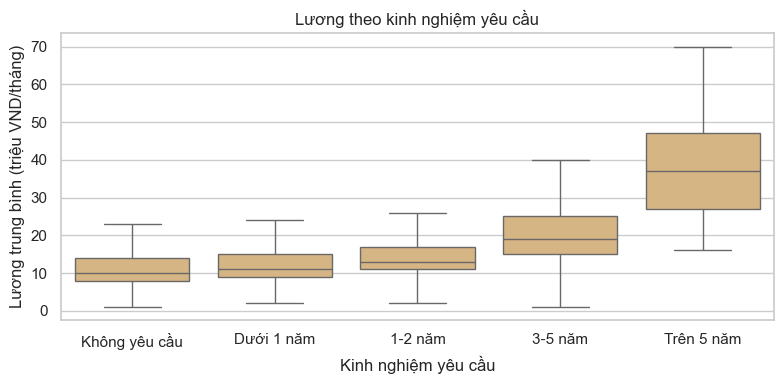

In [2]:
levels = [l for l in EXPERIENCE_LEVELS if l != "Không rõ"]
by_lvl = sal.groupby("experience_level", observed=True)["salary_avg_num"].agg(["count", "median", "mean"]).reindex(levels).round(1)
display(by_lvl)
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=sal, x="experience_level", y="salary_avg_num", order=levels, showfliers=False, ax=ax, color="#e3b778")
ax.set(xlabel="Kinh nghiệm yêu cầu", ylabel="Lương trung bình (triệu VND/tháng)", title="Lương theo kinh nghiệm yêu cầu")
savefig("q2_salary_by_experience.png")

## 2. Hồi quy log-lương theo số tháng kinh nghiệm, từng ngành

,n,β/tháng,% tăng/năm,R²,p
ngành,,,,,
Marketing/Truyền thông,4253,0.0247,34.5,0.267,1.429473e-288
Nhân sự/Hành chính,1821,0.0194,26.3,0.312,6.705490e-150
Kinh doanh/CSKH,3626,0.0179,23.9,0.159,2.007090e-138
Thiết kế/Nghệ thuật,1395,0.0175,23.4,0.302,7.686053e-111
Du lịch/Nhà hàng,2437,0.0165,22.0,0.143,1.244693e-83
Toàn bộ,25796,0.0164,21.8,0.204,0.000000e+00
Tài chính/Kế toán,3156,0.0159,21.0,0.272,5.366271e-220
Sản xuất/Cơ khí,2849,0.0132,17.2,0.184,4.275263e-128
Xây dựng/BĐS,1889,0.0095,12.0,0.143,2.306469e-65


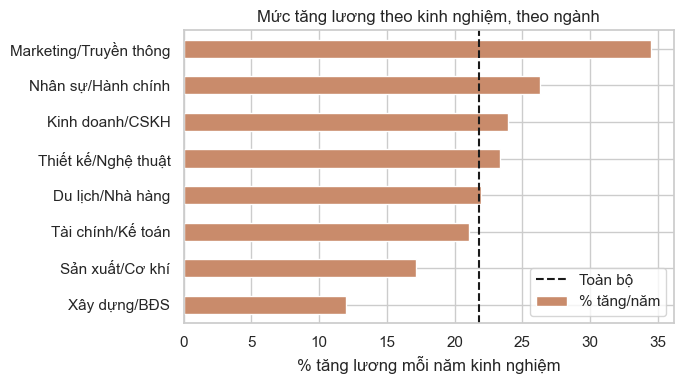

In [3]:
from scipy.stats import linregress
rows = []
top_cats = sal["cat"].value_counts().head(8).index
for name, g in [("Toàn bộ", sal)] + [(c, sal[sal.cat == c]) for c in top_cats]:
    r = linregress(g["experience_months"], np.log(g["salary_avg_num"]))
    rows.append({"ngành": name, "n": len(g), "β/tháng": r.slope, "% tăng/năm": (np.exp(12 * r.slope) - 1) * 100,
                 "R²": r.rvalue ** 2, "p": r.pvalue})
growth = pd.DataFrame(rows).set_index("ngành").sort_values("% tăng/năm", ascending=False)
display(growth.round({"β/tháng": 4, "% tăng/năm": 1, "R²": 3}))
fig, ax = plt.subplots(figsize=(7, 4))
growth["% tăng/năm"].drop("Toàn bộ").sort_values().plot.barh(ax=ax, color="#c98b6b")
ax.axvline(growth.loc["Toàn bộ", "% tăng/năm"], ls="--", c="k", label="Toàn bộ")
ax.set(xlabel="% tăng lương mỗi năm kinh nghiệm", ylabel="", title="Mức tăng lương theo kinh nghiệm, theo ngành")
ax.legend()
savefig("q2_growth_by_category.png")

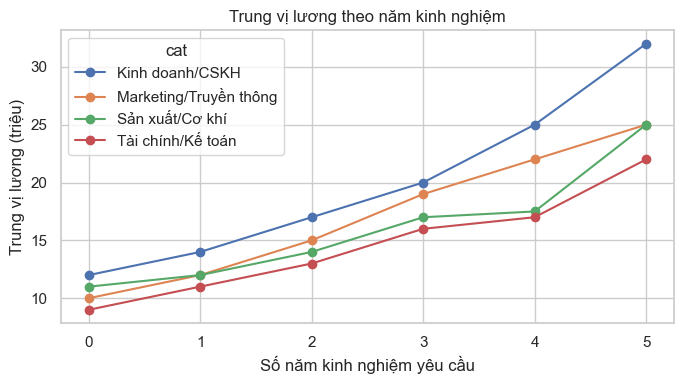

In [4]:
# Trung vị lương theo năm kinh nghiệm (0–5 năm) cho 4 ngành nhiều tin nhất
tmp = sal[sal.experience_months <= 60].assign(years=lambda d: (d.experience_months // 12).astype(int))
curve = tmp[tmp.cat.isin(top_cats[:4])].groupby(["cat", "years"])["salary_avg_num"].median().unstack(0)
ax = curve.plot(marker="o", figsize=(7, 4))
ax.set(xlabel="Số năm kinh nghiệm yêu cầu", ylabel="Trung vị lương (triệu)", title="Trung vị lương theo năm kinh nghiệm")
savefig("q2_salary_curve.png")

## 3. Kết luận

In [5]:
t = growth.drop("Toàn bộ")
print(f"- Tổng thể, mỗi năm kinh nghiệm yêu cầu gắn với lương đăng tuyển cao hơn ≈ {growth.loc['Toàn bộ', '% tăng/năm']:.1f}%.")
print(f"- Trung vị: 'Không yêu cầu' {by_lvl.loc['Không yêu cầu', 'median']:.0f} → '1-2 năm' {by_lvl.loc['1-2 năm', 'median']:.0f} → "
      f"'3-5 năm' {by_lvl.loc['3-5 năm', 'median']:.0f} → 'Trên 5 năm' {by_lvl.loc['Trên 5 năm', 'median']:.0f} triệu.")
print(f"- Tăng nhanh nhất: {t.index[0]} ({t['% tăng/năm'].iloc[0]:.1f}%/năm); chậm nhất: {t.index[-1]} ({t['% tăng/năm'].iloc[-1]:.1f}%/năm).")
print(f"- R² tổng thể ≈ {growth.loc['Toàn bộ', 'R²']:.2f}: kinh nghiệm chỉ giải thích một phần biến động lương.")

- Tổng thể, mỗi năm kinh nghiệm yêu cầu gắn với lương đăng tuyển cao hơn ≈ 21.8%.
- Trung vị: 'Không yêu cầu' 10 → '1-2 năm' 13 → '3-5 năm' 19 → 'Trên 5 năm' 37 triệu.
- Tăng nhanh nhất: Marketing/Truyền thông (34.5%/năm); chậm nhất: Xây dựng/BĐS (12.0%/năm).
- R² tổng thể ≈ 0.20: kinh nghiệm chỉ giải thích một phần biến động lương.


**Hạn chế chung:** dữ liệu chỉ từ TopCV (2025), là **lương đăng tuyển** (không phải lương thực nhận),
và ~29% tin không công bố lương. Kết luận chỉ mô tả thị trường tin tuyển dụng trên nền tảng này.

Kinh nghiệm ở đây là kinh nghiệm **yêu cầu** trong tin, không phải kinh nghiệm thực của ứng viên.
*Nhận xét trên được sinh tự động từ số liệu — thành viên phụ trách cần đọc lại và diễn giải bằng lời của mình.*